# Análisis exploratorio de datos

## Carga de datos

In [1]:
import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss

sns.set_style("whitegrid")
sns.set_context("notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e6e6e3", "lines.linewidth": 1.2})

# Paleta categórica fija (siempre en este orden)
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"

FIG_DIR = Path("../figuras")
FIG_DIR.mkdir(exist_ok=True)

In [2]:
pd.set_option("display.max_columns", None)  # Para ver todas las columnas del DataFrame
pd.set_option("display.width", 200)

In [3]:
DATA_PATH_GEN_DIARIA = Path("../data/raw/ree_generacion_diaria.csv")
DATA_PATH_HORARIO = Path("../data/raw/ree_horario.csv")

if not DATA_PATH_GEN_DIARIA.exists():
    # Alternativa si se ejecuta desde la raíz del proyecto
    DATA_PATH_GEN_DIARIA = Path("data/raw/ree_generacion_diaria.csv")

if not DATA_PATH_HORARIO.exists():
    # Alternativa si se ejecuta desde la raíz del proyecto
    DATA_PATH_HORARIO = Path("data/raw/ree_horario.csv")

df_horario = pd.read_csv(DATA_PATH_HORARIO)
df_generacion = pd.read_csv(DATA_PATH_GEN_DIARIA)

print(
    f"✓ Dataset cargado correctamente con {df_horario.shape[0]} filas y {df_horario.shape[1]} columnas a partir de ree_horario.csv."
)
print(
    f"✓ Dataset cargado correctamente con {df_generacion.shape[0]} filas y {df_generacion.shape[1]} columnas a partir de ree_generacion_diaria.csv."
)
assert df_horario.shape == (
    26280,
    6,
), f"Dimensiones inesperadas: {df_horario.shape} (se esperaban 26280 filas y 6 columnas)"

assert df_generacion.shape == (
    1095,
    18,
), f"Dimensiones inesperadas: {df_generacion.shape} (se esperaban 1095 filas y 18 columnas)"

df_horario.head()

✓ Dataset cargado correctamente con 26280 filas y 6 columnas a partir de ree_horario.csv.
✓ Dataset cargado correctamente con 1095 filas y 18 columnas a partir de ree_generacion_diaria.csv.


,fecha_hora,demanda_prevista,demanda_programada,demanda_real,precio_spot,pvpc
0,2021-01-01 00:00:00+01:00,26104.667,26013.0,26151.667,50.87,NaN
1,2021-01-01 01:00:00+01:00,24822.583,24630.0,24886.250,48.19,NaN
2,2021-01-01 02:00:00+01:00,22652.667,22696.0,22685.500,44.68,NaN
3,2021-01-01 03:00:00+01:00,20786.833,20756.0,20828.250,38.50,NaN
4,2021-01-01 04:00:00+01:00,19877.917,19800.0,19877.583,36.80,NaN


In [4]:
df_generacion.head()

,fecha,gen_hidráulica,gen_nuclear,gen_carbón,gen_motores_diésel,gen_turbina_de_gas,gen_turbina_de_vapor,gen_ciclo_combinado,gen_hidroeólica,gen_eólica,gen_solar_fotovoltaica,gen_solar_térmica,gen_otras_renovables,gen_cogeneración,gen_residuos_no_renovables,gen_residuos_renovables,gen_generación_total,gen_fuel_gas
0,2021-01-01,111077.579,170966.633,5663.327,6180.245,840.614,3681.076,61416.329,15.538,240290.824,29876.523,3126.095,13234.386,54581.986,4477.651,1232.274,706661.080,NaN
1,2021-01-02,112211.332,170974.655,5611.373,7074.243,722.388,4587.264,80555.288,1.957,270599.158,34247.163,6340.881,12636.823,67513.021,4389.159,1262.089,778726.794,NaN
2,2021-01-03,116969.983,171000.851,5597.198,7036.465,993.803,4502.216,83628.611,15.593,221167.693,37134.485,7441.714,12215.001,73185.396,4896.856,1250.171,747036.037,NaN
3,2021-01-04,165965.559,170871.508,8431.686,7371.259,1328.929,3783.796,144897.990,34.367,130542.499,26307.981,2783.566,12124.513,77455.663,5155.834,1215.017,758270.167,NaN
4,2021-01-05,176184.581,170882.098,16295.678,7285.896,1006.802,4453.566,138876.901,-3.059,70360.924,29746.352,2099.695,12386.598,80838.906,5499.507,1230.110,717144.555,NaN


Se comienza analizando `df_horario`, ya que contiene la variable `demanda_real`, que es la que se busca predecir. Sin embargo, se puede observar que viene en horas, mientras que el segundo fichero viene en días, por lo que será necesario más adelante una conversión a días.

In [5]:
df_horario.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26280 entries, 0 to 26279
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   fecha_hora          26280 non-null  object 
 1   demanda_prevista    26172 non-null  float64
 2   demanda_programada  26172 non-null  float64
 3   demanda_real        26178 non-null  float64
 4   precio_spot         26280 non-null  float64
 5   pvpc                22657 non-null  float64
dtypes: float64(5), object(1)
memory usage: 1.2+ MB


Se observa que la variable `fecha_hora` viene en formato `object` en vez de `datetime`, por lo que conviene realizar una conversión, especialmente para poder tener los datos ordenados por fecha. En principio, en el head() se muestra que siguen un formato ISO 8601 con la fecha (año-mes-día), la hora (horas:minutos:segundos) y un desfase respecto a UTC, pero habrá que comprobar si realmente todos los valores en `datetime` siguen este formato, además de comprobar si hay nulos y posteriormente cuando se realiza la conversión analizar si hay fechas duplicadas o temporalmente ausentes.

In [6]:
nulos = df_horario.isnull().sum()
print("Valores nulos por columna en df_horario:")
print(nulos)

Valores nulos por columna en df_horario:
fecha_hora               0
demanda_prevista       108
demanda_programada     108
demanda_real           102
precio_spot              0
pvpc                  3623
dtype: int64


Al encontrarse valores nulos en el dataset de horario, no se debería hacer una conversión a días directamente en el preprocesamiento sin haber tratado estos nulos previamente, ya que al realizar la suma se perdería información en las horas faltantes, lo que resulta crítico en `demanda_real`, que es la variable objetivo. Hay 108 nulos en `demanda_prevista`, 108 nulos en `demanda_programada`, 102 nulos en `demanda_real` y 3623 nulos en `pvpc`. En cuanto a la conversión de `fecha_hora`, no presenta fechas ausentes a priori. Falta comprobar si el formato ISO 8601 se cumple para todos los valores.

In [7]:
print("Distribución de la longitud (en caracteres) de los datos en 'fecha_hora'\n:" + str(df_horario['fecha_hora'].astype(str).str.len().value_counts()))
print("Desfases encontrados:\n" + str(df_horario['fecha_hora'].astype(str).str[-6:].value_counts()))

fechas_test = pd.to_datetime(df_horario['fecha_hora'], errors='coerce', utc=True)
filas_problematicas = df_horario[fechas_test.isna() & df_horario['fecha_hora'].notna()]

if len(filas_problematicas) > 0:
    print(f"Hay {len(filas_problematicas)} filas que no se pueden convertir a datetime.")
else:
    print("Todas las filas se pueden convertir a datetime correctamente.")

Distribución de la longitud (en caracteres) de los datos en 'fecha_hora'
:fecha_hora
25    26280
Name: count, dtype: int64
Desfases encontrados:
fecha_hora
+02:00    15624
+01:00    10656
Name: count, dtype: int64
Todas las filas se pueden convertir a datetime correctamente.


Todos los registros de `fecha_hora` tienen exactamente 25 caracteres y ninguno falla al convertirse a `datetime`. Además, aparecen dos desfases distintos (`+02:00` en 15.624 filas, siendo el horario de verano, y `+01:00` en 10.656 filas, siendo el horario de invierno), lo que confirma que en el dataset ya vienen reflejados los cambios entre horario de invierno y verano del sistema peninsular. Con esto ya se puede pasar la columna a `datetime` y revisar después si hay duplicados, huecos temporales o días con más o menos de 24 horas cuando se agrupen por día.

In [8]:
df_horario['fecha_hora'] = pd.to_datetime(df_horario['fecha_hora'], utc=True).dt.tz_convert('Europe/Madrid')
df_horario = df_horario.sort_values('fecha_hora')
df_horario.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26280 entries, 0 to 26279
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype                        
---  ------              --------------  -----                        
 0   fecha_hora          26280 non-null  datetime64[ns, Europe/Madrid]
 1   demanda_prevista    26172 non-null  float64                      
 2   demanda_programada  26172 non-null  float64                      
 3   demanda_real        26178 non-null  float64                      
 4   precio_spot         26280 non-null  float64                      
 5   pvpc                22657 non-null  float64                      
dtypes: datetime64[ns, Europe/Madrid](1), float64(5)
memory usage: 1.2 MB


Al pasar a `datetime` se convierte a `Europe/Madrid` en lugar de dejarlo en UTC para no desajustar la serie frente a la fecha diaria de `ree_generacion_diaria.csv`, además de que permite analizar el comportamiento de la demanda y los precios según la hora real en España.

In [9]:
# Comprobar si hay fechas duplicadas
print(f"Hay {df_horario['fecha_hora'].duplicated().sum()} fechas duplicadas.")

# Comprobar los huecos temporales (en horas)
rango_ideal = pd.date_range(start=df_horario['fecha_hora'].min(), end=df_horario['fecha_hora'].max(), freq='1h')
horas_faltantes = rango_ideal.difference(df_horario['fecha_hora'])
print(f"\nHay {len(horas_faltantes)} horas faltantes en el rango temporal.")
if len(horas_faltantes) > 0:
    for hora in horas_faltantes:
        print(hora)

# Comprobar qué días están incompletos
conteo_por_dia = df_horario.groupby(df_horario['fecha_hora'].dt.date).size()
dias_incompletos = conteo_por_dia[conteo_por_dia != 24]
print(f"\nHay {len(dias_incompletos)} días incompletos:")
for dia, num_horas in dias_incompletos.items():
    print(f"{dia}: {num_horas} horas registradas")

# Primer y último registro
print(f"\nPrimer registro: {df_horario['fecha_hora'].min()}")
print(f"Último registro: {df_horario['fecha_hora'].max()}")

Hay 0 fechas duplicadas.

Hay 0 horas faltantes en el rango temporal.

Hay 6 días incompletos:
2021-03-28: 23 horas registradas
2021-10-31: 25 horas registradas
2022-03-27: 23 horas registradas
2022-10-30: 25 horas registradas
2023-03-26: 23 horas registradas
2023-10-29: 25 horas registradas

Primer registro: 2021-01-01 00:00:00+01:00
Último registro: 2023-12-31 23:00:00+01:00


No hay fechas duplicadas ni horas faltantes en todo el rango temporal, que va desde 2021-01-01 00:00:00+01:00 hasta 2023-12-31 23:00:00+01:00, y cubre todos los días en el rango temporal, sin haber ningún día ausente. En cuanto a los días incompletos, no se encuentra ninguno debido a pérdida de datos, puesto que los seis días con 23 o 25 horas registradas corresponden a los cambios de hora de verano e invierno en hora peninsular y no a huecos en los datos, algo que convendrá tener en cuenta al pasar a diario. Tampoco el primer registro o el último registro aparecen como incompletos, por lo que el dataset contiene la información completa de ambos días.

In [10]:
pct_nulos = (df_horario.isnull().sum() / len(df_horario)) * 100
df_nulos = pd.DataFrame(
    {"Nulos": nulos, "Porcentaje (%)": pct_nulos.round(2)}
).query("Nulos > 0")
if len(df_nulos) > 0:
    print(df_nulos.sort_values(by="Porcentaje (%)", ascending=False))
else:
    print("No se han detectado valores nulos explícitos (NaN).")

                    Nulos  Porcentaje (%)
pvpc                 3623           13.79
demanda_prevista      108            0.41
demanda_programada    108            0.41
demanda_real          102            0.39


Ahora que se ha confirmado que no hay huecos temporales en el rango temporal del dataset, se puede comprobar el porcentaje de valores nulos por columna de cara a decidir en un futuro preprocesamiento si se deberían imputar, conservar o descartar. Los resultados muestran en general un número de valores ausentes muy reducido. Sin embargo, `pvpc` contiene un porcentaje considerable de valores nulos, siendo del 13.79%, por lo que habrá que estudiar esta variable con mayor detenimiento para tomar una decisión en el preprocesamiento sobre cómo tratar dicha columna.

### Patrón temporal de los valores nulos

El porcentaje de nulos no dice nada de **cómo** se distribuyen. En una serie temporal no es lo mismo que falten horas sueltas repartidas al azar (se pueden interpolar sin problema) que bloques largos y seguidos. Por eso se buscan los tramos consecutivos de nulos de cada columna.

In [11]:
def bloques_nulos(serie, fechas):
    """Devuelve los tramos consecutivos de nulos de una serie (inicio, fin y número de horas)."""
    es_nulo = serie.isna()
    id_bloque = (es_nulo != es_nulo.shift()).cumsum()[es_nulo]
    return (pd.DataFrame({"fecha_hora": fechas[es_nulo], "bloque": id_bloque})
              .groupby("bloque")["fecha_hora"].agg(inicio="min", fin="max", horas="size")
              .reset_index(drop=True))

for col in ["demanda_real", "demanda_prevista", "demanda_programada", "pvpc"]:
    print(f"--- {col}")
    print(bloques_nulos(df_horario[col], df_horario["fecha_hora"]).to_string(), "\n")

--- demanda_real
                     inicio                       fin  horas
0 2021-05-22 04:00:00+02:00 2021-05-22 20:00:00+02:00     17
1 2021-11-07 04:00:00+01:00 2021-11-07 20:00:00+01:00     17
2 2022-07-27 04:00:00+02:00 2022-07-27 20:00:00+02:00     17
3 2022-12-13 04:00:00+01:00 2022-12-13 20:00:00+01:00     17
4 2023-04-18 04:00:00+02:00 2023-04-18 20:00:00+02:00     17
5 2023-11-05 04:00:00+01:00 2023-11-05 20:00:00+01:00     17 

--- demanda_prevista
                     inicio                       fin  horas
0 2021-05-22 03:00:00+02:00 2021-05-22 20:00:00+02:00     18
1 2022-03-06 03:00:00+01:00 2022-03-06 20:00:00+01:00     18
2 2022-06-29 03:00:00+02:00 2022-06-29 20:00:00+02:00     18
3 2022-12-19 03:00:00+01:00 2022-12-19 20:00:00+01:00     18
4 2023-04-12 03:00:00+02:00 2023-04-12 20:00:00+02:00     18
5 2023-10-03 03:00:00+02:00 2023-10-03 20:00:00+02:00     18 

--- demanda_programada
                     inicio                       fin  horas
0 2021-05-22 03:00:0

Los nulos **no son aleatorios**:

- `demanda_real` tiene 6 bloques de exactamente 17 horas (de 04:00 a 20:00) en seis días concretos, uno por semestre más o menos. En esos días solo hay datos de la madrugada y de la noche, que son las horas de menor consumo. Si se agregase a diario con una media o una suma ignorando los nulos, la demanda de esos días saldría muy por debajo de la real, así que hay que imputar **antes** de agregar.
- `demanda_prevista` y `demanda_programada` tienen 6 bloques de 18 horas (03:00 a 20:00) y siempre coinciden entre sí. Solo comparten día con los huecos de `demanda_real` el 2021-05-22. En los otros cinco días con hueco en `demanda_real` la previsión de REE sí está disponible.
- `pvpc` tiene un único bloque: falta todo del 1 de enero al 31 de mayo de 2021. Coincide con la entrada en vigor de la tarifa 2.0TD (1 de junio de 2021), que cambió la forma de calcular el PVPC, así que es un hueco **estructural** que no tiene sentido imputar.

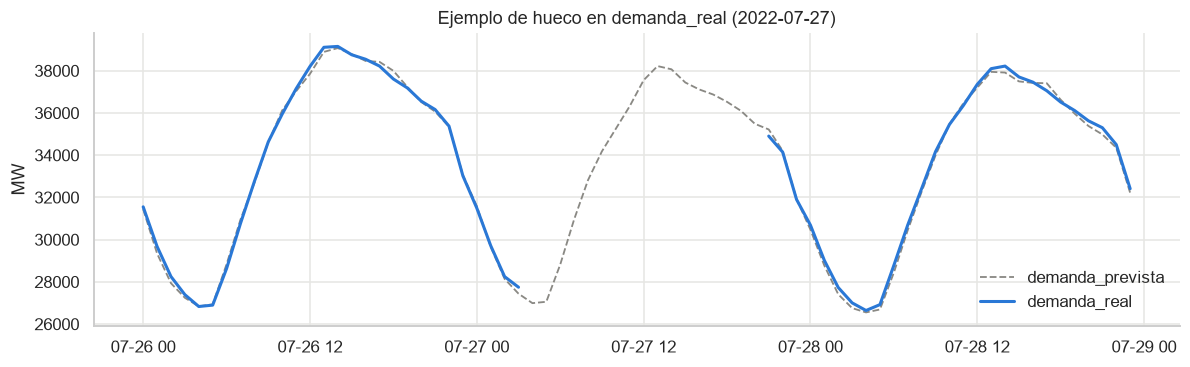

Error relativo horario de demanda_prevista: media 0.12%, error absoluto medio 0.54%, máximo 5.56%


In [12]:
dia = "2022-07-27"
tramo = df_horario[df_horario["fecha_hora"].dt.strftime("%Y-%m-%d").between("2022-07-26", "2022-07-28")]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(tramo["fecha_hora"], tramo["demanda_prevista"], color=GRIS, ls="--", label="demanda_prevista")
ax.plot(tramo["fecha_hora"], tramo["demanda_real"], color=AZUL, lw=2, label="demanda_real")
ax.set_title(f"Ejemplo de hueco en demanda_real ({dia})")
ax.set_ylabel("MW")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_hueco_demanda.png", bbox_inches="tight")
plt.show()

err = (df_horario["demanda_real"] - df_horario["demanda_prevista"]) / df_horario["demanda_real"]
print(f"Error relativo horario de demanda_prevista: media {err.mean():.2%}, "
      f"error absoluto medio {err.abs().mean():.2%}, máximo {err.abs().max():.2%}")

La previsión de REE sigue casi exactamente a la demanda real: su error absoluto medio por hora está por debajo del 1 %. Esto será útil en el preprocesado para rellenar los huecos de `demanda_real` cuando la previsión exista. Ojo: rellenar huecos históricos con ella es una decisión de limpieza; usarla como variable de entrada del modelo es otra cosa (ver el apartado de variables exógenas).

## Dataset de generación diaria

In [13]:
df_generacion["fecha"] = pd.to_datetime(df_generacion["fecha"])
df_generacion = df_generacion.sort_values("fecha").reset_index(drop=True)
df_generacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   fecha                       1095 non-null   datetime64[ns]
 1   gen_hidráulica              1095 non-null   float64       
 2   gen_nuclear                 1095 non-null   float64       
 3   gen_carbón                  1095 non-null   float64       
 4   gen_motores_diésel          1095 non-null   float64       
 5   gen_turbina_de_gas          1095 non-null   float64       
 6   gen_turbina_de_vapor        1095 non-null   float64       
 7   gen_ciclo_combinado         1095 non-null   float64       
 8   gen_hidroeólica             1095 non-null   float64       
 9   gen_eólica                  1095 non-null   float64       
 10  gen_solar_fotovoltaica      1095 non-null   float64       
 11  gen_solar_térmica           1095 non-null   float64     

In [14]:
print(f"Fechas duplicadas: {df_generacion['fecha'].duplicated().sum()}")
dias_faltan = pd.date_range(df_generacion["fecha"].min(), df_generacion["fecha"].max(), freq="D").difference(df_generacion["fecha"])
print(f"Días ausentes: {len(dias_faltan)}  (rango {df_generacion['fecha'].min().date()} a {df_generacion['fecha'].max().date()})")

print("\nValores no nulos de gen_fuel_gas:")
print(df_generacion.loc[df_generacion["gen_fuel_gas"].notna(), ["fecha", "gen_fuel_gas"]].to_string(index=False))

cols_gen = df_generacion.columns.drop("fecha")
negativos = (df_generacion[cols_gen] < 0).sum()
print("\nDías con generación negativa por tecnología:")
print(pd.DataFrame({"dias": negativos, "minimo": df_generacion[cols_gen].min()})[negativos > 0])

componentes = cols_gen.drop(["gen_generación_total", "gen_fuel_gas"])
dif = (df_generacion[componentes].sum(axis=1) - df_generacion["gen_generación_total"]).abs().max()
print(f"\nMáxima diferencia entre la suma de tecnologías y gen_generación_total: {dif:.6f} MWh")

Fechas duplicadas: 0
Días ausentes: 0  (rango 2021-01-01 a 2023-12-31)

Valores no nulos de gen_fuel_gas:
     fecha  gen_fuel_gas
2021-07-25        -0.001
2021-08-08         0.001
2021-08-19        -0.001
2021-09-12         0.001
2021-09-18        -0.001
2022-09-25        -0.001
2022-09-29         0.001
2022-10-20        -0.001
2022-10-27         0.001
2023-07-22         0.001

Días con generación negativa por tecnología:
                 dias   minimo
gen_carbón          5 -643.438
gen_hidroeólica    31   -4.074
gen_fuel_gas        5   -0.001

Máxima diferencia entre la suma de tecnologías y gen_generación_total: 0.002000 MWh


In [15]:
df_generacion.describe().T

,count,mean,min,25%,50%,75%,max,std
fecha,1095,2022-07-02 00:00:00,2021-01-01 00:00:00,2021-10-01 12:00:00,2022-07-02 00:00:00,2023-04-01 12:00:00,2023-12-31 00:00:00,NaN
gen_hidráulica,1095.0,66942.358034,12758.185,38984.556,56974.886,84145.1545,191711.084,37301.062707
gen_nuclear,1095.0,150340.230647,78628.552,141400.9835,160035.897,166872.536,171217.822,20694.876399
gen_carbón,1095.0,15298.393775,-643.438,8391.235,13149.289,19812.1355,44393.346,8216.676321
gen_motores_diésel,1095.0,6964.700805,4692.076,6273.3425,6965.661,7614.3805,9924.464,962.544914
gen_turbina_de_gas,1095.0,1682.470047,143.818,1017.022,1549.845,2215.893,4798.724,869.111475
gen_turbina_de_vapor,1095.0,3260.441907,563.573,2837.9245,3315.036,3852.3805,5795.686,888.252463
gen_ciclo_combinado,1095.0,145497.553359,33657.933,85450.9545,129223.333,184177.5015,396453.645,77672.841302
gen_hidroeólica,1095.0,58.304366,-4.074,16.369,49.576,96.0055,155.1,45.204029
gen_eólica,1095.0,168395.100381,20866.063,102053.0695,151098.202,221158.97,430064.376,87870.7198


El fichero de generación tiene todos los días del periodo, sin duplicados, pero hay tres cosas que tener en cuenta:

- `gen_fuel_gas` está vacía en 1.085 de 1.095 días, y los 10 valores que tiene son ±0,001 MWh, es decir, cero. Es una columna sin información y se eliminará.
- `gen_carbón` y `gen_hidroeólica` tienen algunos días negativos. No son errores: en REE la generación es **neta**, así que una central parada que consume de la red para sus servicios auxiliares aparece con generación negativa. Los valores son pequeños comparados con el resto y no hace falta corregirlos.
- `gen_generación_total` es exactamente la suma de las demás tecnologías, así que es redundante con ellas.

Además, la generación diaria es del **mismo día** que la demanda. Para predecir t+1…t+7 en el día t, la generación de esos días aún no existe, así que, si se usa, tiene que entrar retrasada.

## Serie objetivo: demanda real diaria

### Cómo pasar de horas a días

`demanda_real` es una potencia media horaria (MW). Hay dos maneras de pasarla a diaria:

- **Suma** de las horas: da la energía del día en MWh. El problema es que los días de cambio de hora tienen 23 o 25 horas, así que su energía sale en torno a un 4 % más baja o más alta por un efecto que no tiene nada que ver con el consumo.
- **Media** de las horas: da la potencia media del día en MW, en la misma unidad que el dato original, y no le afecta el número de horas del día.

Se usa la **media diaria** (en MW). Para el EDA, los seis días con hueco en `demanda_real` se dejan como nulos (se exige tener al menos 23 horas con dato) en vez de calcular una media sesgada con solo 7 horas. La imputación de verdad se hace en el preprocesado.

Esta agregación es solo exploratoria; la serie definitiva (con imputación) se construye en el preprocesado

In [16]:
h = df_horario.set_index("fecha_hora")
diario = h["demanda_real"].resample("D").agg(["mean", "sum", "count"])
diario.index = diario.index.tz_localize(None)
horas_dia = h["demanda_real"].resample("D").size()
horas_dia.index = horas_dia.index.tz_localize(None)

# Efecto de los cambios de hora sobre la suma diaria
cambio_hora = horas_dia[horas_dia != 24].index
efecto = (diario.loc[cambio_hora, "sum"] / (diario.loc[cambio_hora, "mean"] * 24) - 1).rename("suma vs media*24")
print(pd.concat([horas_dia[cambio_hora].rename("horas"), efecto.map("{:+.1%}".format)], axis=1))

demanda = diario["mean"].where(diario["count"] >= 23).rename("demanda_real")
print(f"\nDías sin demanda diaria válida (hueco de 17 h): {demanda.isna().sum()}")
demanda.describe()

            horas suma vs media*24
fecha_hora                        
2021-03-28     23            -4.2%
2021-10-31     25            +4.2%
2022-03-27     23            -4.2%
2022-10-30     25            +4.2%
2023-03-26     23            -4.2%
2023-10-29     25            +4.2%

Días sin demanda diaria válida (hueco de 17 h): 6


count     1089.000000
mean     28684.525760
std       2927.019857
min      20500.045125
25%      26698.656292
50%      28822.444542
75%      30766.256958
max      36930.180583
Name: demanda_real, dtype: float64

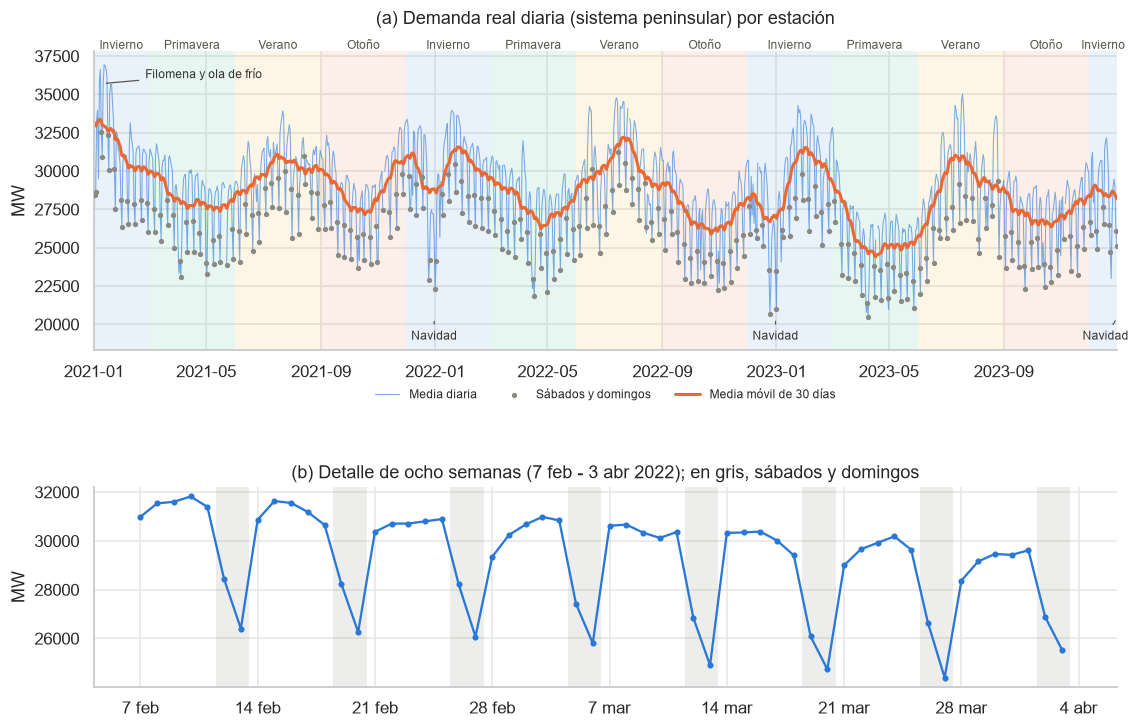

Navidad 2021-2022: semana 13-17 dic 32,615 MW | 24 dic-6 ene 26,336 MW (-19.3%) | mínimo 22,330 MW el 01-01-2022
Navidad 2022-2023: semana 13-17 dic 29,149 MW | 24 dic-6 ene 25,075 MW (-14.0%) | mínimo 20,692 MW el 25-12-2022


In [17]:
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

media_movil = demanda.rolling(30, center=True, min_periods=15).mean()
finde = demanda.index.dayofweek >= 5

# Estaciones meteorológicas: invierno dic-feb, primavera mar-may, verano jun-ago, otoño sep-nov
ESTACIONES = {12: ("Invierno", AZUL), 3: ("Primavera", AQUA), 6: ("Verano", AMARILLO), 9: ("Otoño", NARANJA)}
inicios = pd.date_range("2020-12-01", "2024-03-01", freq="3MS")

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), gridspec_kw={"height_ratios": [1.5, 1], "hspace": 0.55})

# (a) Serie completa con las estaciones sombreadas
ax = axes[0]
for ini, fin in zip(inicios[:-1], inicios[1:]):
    nombre, color = ESTACIONES[ini.month]
    a, b = max(ini, demanda.index[0]), min(fin, demanda.index[-1] + pd.Timedelta(days=1))
    ax.axvspan(a, b, color=color, alpha=0.10, lw=0)
    ax.text(a + (b - a) / 2, 1.0, nombre, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
            fontsize=8, color="#55554f")
ax.plot(demanda.index, demanda, color=AZUL, lw=0.7, alpha=0.6, label="Media diaria")
ax.scatter(demanda.index[finde], demanda[finde], s=6, color=GRIS, zorder=3, label="Sábados y domingos")
ax.plot(media_movil.index, media_movil, color=NARANJA, lw=2, label="Media móvil de 30 días")
# Episodios que se comentan en el texto
ax.annotate("Filomena y ola de frío", xy=(pd.Timestamp("2021-01-11"), demanda["2021-01-11"]),
            xytext=(pd.Timestamp("2021-02-25"), 36300), fontsize=8, color="#33332f", va="center",
            arrowprops={"arrowstyle": "-", "color": "#55554f", "lw": 0.8})
for anio in [2021, 2022, 2023]:
    centro = pd.Timestamp(f"{anio}-12-31")
    ax.annotate("Navidad", xy=(min(centro, demanda.index[-1]), 20400), xytext=(min(centro, demanda.index[-1] - pd.Timedelta(days=12)), 19000),
                ha="center", fontsize=8, color="#33332f",
                arrowprops={"arrowstyle": "-", "color": "#55554f", "lw": 0.8})
ax.set_title("(a) Demanda real diaria (sistema peninsular) por estación", pad=18)
ax.set_ylabel("MW")
ax.set_xlim(demanda.index[0], demanda.index[-1])
ax.set_ylim(18300, 37800)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, fontsize=8)

# (b) Zoom de ocho semanas para ver el patrón semanal
zoom = demanda["2022-02-07":"2022-04-03"]
ax = axes[1]
for dia in zoom.index[zoom.index.dayofweek == 5]:
    ax.axvspan(dia - pd.Timedelta(hours=12), dia + pd.Timedelta(hours=36), color=GRIS, alpha=0.15, lw=0)
ax.plot(zoom.index, zoom, color=AZUL, lw=1.5, marker="o", ms=3)
ax.set_title("(b) Detalle de ocho semanas (7 feb - 3 abr 2022); en gris, sábados y domingos")
ax.set_ylabel("MW")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: (lambda d: f"{d.day} {MESES[d.month - 1]}")(mdates.num2date(x))))

fig.savefig(FIG_DIR / "eda_serie_diaria.png", bbox_inches="tight")
plt.show()

# Caída de Navidad: media de la semana laborable previa frente al periodo 24-dic a 6-ene
for anio in [2021, 2022]:
    antes = demanda[f"{anio}-12-13":f"{anio}-12-17"].mean()
    navidad = demanda[f"{anio}-12-24":f"{anio + 1}-01-06"]
    print(f"Navidad {anio}-{anio + 1}: semana 13-17 dic {antes:,.0f} MW | 24 dic-6 ene {navidad.mean():,.0f} MW "
          f"({navidad.mean() / antes - 1:+.1%}) | mínimo {navidad.min():,.0f} MW el {navidad.idxmin():%d-%m-%Y}")

La serie no tiene huecos aparte de los seis días mencionados y se mueve entre unos 20.500 y 36.900 MW, con una media de unos 28.700 MW. En la gráfica se ve:

- **Estacionalidad semanal** muy marcada. En (a), los puntos grises (sábados y domingos) quedan casi siempre en la parte baja del "dentado" de la serie. En el detalle (b) se ve mejor: de lunes a viernes la demanda se mantiene estable, baja el sábado, llega al mínimo el domingo y se recupera el lunes. Es un ciclo de 7 días que se repite todas las semanas.
- **Estacionalidad anual** con dos máximos cada año: uno en invierno (calefacción e iluminación), sobre todo en enero, y otro en verano (refrigeración), sobre todo en julio. Los mínimos caen en primavera y otoño, que son las estaciones de temperaturas más suaves.
- **Tendencia ligeramente decreciente** a lo largo de los tres años.

En el invierno de 2021-2022 la media móvil baja a finales de diciembre y vuelve a subir a mediados de enero. Es el efecto de la **Navidad**: entre el 24 de diciembre y el 6 de enero la demanda media fue de 26.336 MW, un 19 % menos que en la semana laborable del 13 al 17 de diciembre (32.615 MW), y el 1 de enero bajó a 22.330 MW. Entre festivos, puentes y vacaciones, muchas oficinas y fábricas reducen o paran la actividad. Como la media móvil de 30 días está centrada, esas dos semanas bajas la arrastran hacia abajo justo en el cambio de año. Lo mismo ocurre en 2022-2023 (−14 %) y a finales de 2023 (aunque ahí la serie termina el 31 de diciembre), pero se nota menos porque la demanda de diciembre ya era más baja. En 2021-2022 la caída queda entre dos tramos de demanda alta (la primera quincena de diciembre y la segunda de enero), y por eso destaca más.

También hay otros episodios puntuales: el pico de principios de enero de 2021 coincide con la borrasca Filomena y la ola de frío posterior, y la Semana Santa provoca caídas bruscas en primavera.

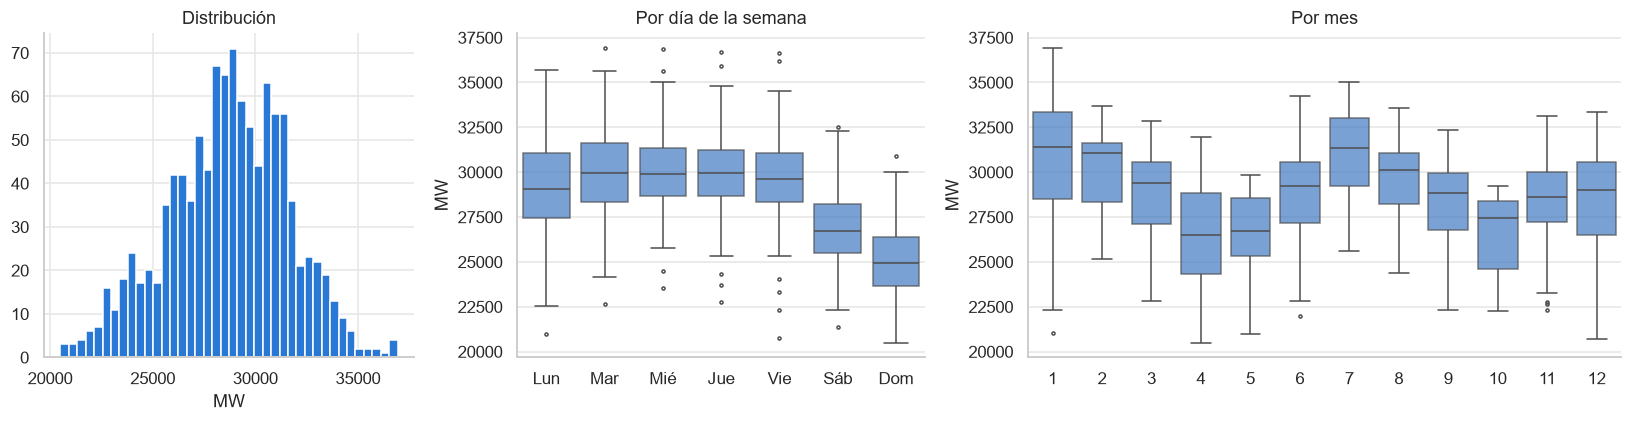

Media por día de la semana (MW):
Lun    29173.0
Mar    30043.0
Mié    30069.0
Jue    30032.0
Vie    29648.0
Sáb    26788.0
Dom    25034.0

Media anual (MW):
anio
2021    29456.0
2022    28652.0
2023    27945.0


In [18]:
df_d = demanda.to_frame()
df_d["dia_semana"] = df_d.index.dayofweek
df_d["mes"] = df_d.index.month
df_d["anio"] = df_d.index.year
nombres_dia = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1.1, 1.6]})
axes[0].hist(demanda.dropna(), bins=40, color=AZUL, edgecolor="white")
axes[0].set_title("Distribución")
axes[0].set_xlabel("MW")
sns.boxplot(data=df_d, x="dia_semana", y="demanda_real", color=AZUL, ax=axes[1], fliersize=2,
            boxprops={"alpha": 0.7})
axes[1].set_xticks(range(7), nombres_dia)
axes[1].set_title("Por día de la semana")
sns.boxplot(data=df_d, x="mes", y="demanda_real", color=AZUL, ax=axes[2], fliersize=2,
            boxprops={"alpha": 0.7})
axes[2].set_title("Por mes")
for ax in axes[1:]:
    ax.set_xlabel("")
    ax.set_ylabel("MW")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_distribucion_estacionalidad.png", bbox_inches="tight")
plt.show()

print("Media por día de la semana (MW):")
print(df_d.groupby("dia_semana")["demanda_real"].mean().set_axis(nombres_dia).round(0).to_string())
print("\nMedia anual (MW):")
print(df_d.groupby("anio")["demanda_real"].mean().round(0).to_string())

Los tres años siguen el mismo perfil anual, pero hay que fijarse en los detalles:

- Cada año está desplazado respecto al anterior por el nivel medio (2023 va casi siempre por debajo).
- La Semana Santa cae en días distintos cada año (2021: 1-5 de abril; 2022: 14-18 de abril; 2023: 6-10 de abril), así que su caída no cuadra en el día del año. Lo mismo ocurre con los puentes. Por eso una variable de calendario de "día del año" no basta para recoger los festivos móviles.
- Hay episodios meteorológicos de un solo año, como la ola de frío de enero de 2021 o el calor de mediados de junio de 2022 (en torno al día 165), que el calendario no puede explicar. No hay datos de temperatura, así que esto quedará como error irreducible del modelo.

### Efecto de los festivos

### Descomposición de la serie

### Estacionariedad y autocorrelación

## Relación con las variables exógenas